# 메시지와 제공자 전환

**이 노트북에서 할 일**

1. 같은 역할과 내용을 튜플 목록과 메시지 객체 목록으로 만들어 같은 모델에 보냅니다.
2. 모델 이름과 제공자 이름을 하나씩 바꿔, 그대로 되는 것과 다시 확인할 것을 나눕니다.
3. 실행함·키 없음·요청 오류를 기록표에 서로 다른 상태로 적습니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.
Anthropic·Google 키는 없어도 됩니다. 이 노트북은 두 제공자에 요청을 보내지 않습니다.

인터넷 서비스에 요청을 모두 4번 보냅니다. `gpt-5.4-mini` 2번, `gpt-5.4-nano` 1번, 없는 모델 이름 1번입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 06절 4절에서 2026-09-17에 확인한 mini·nano 공식 요금 기준입니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
통합 패키지 langchain-anthropic 1.7.1과 langchain-google-genai 4.4.0도 씁니다. pydantic 2.13.5, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch06-langchain-start`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

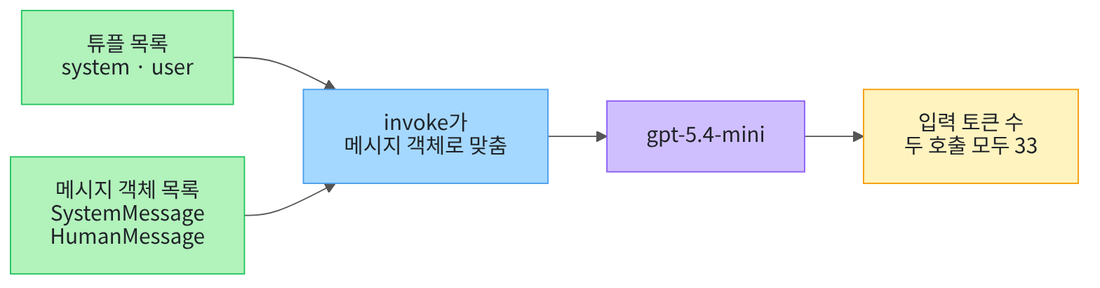

왼쪽에서 오른쪽으로 읽습니다. 초록 상자 두 개는 같은 역할과 내용을 두 가지로 적은 목록입니다.
파란 상자에서 두 목록이 같은 메시지 객체로 맞춰지고, 보라 상자 모델에 요청이 갑니다.
노란 상자는 이 노트북 4절에서 두 호출의 입력 토큰 수를 비교한 결과입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01절보다 두 패키지가 늘었습니다. 콜론 앞 제공자 이름이 anthropic, google_genai일 때 모델 객체를 만드는 패키지입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langchain-anthropic==1.7.1" "langchain-google-genai==4.4.0" "pydantic==2.13.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langchain-anthropic:", version("langchain-anthropic"))
print("langchain-google-genai:", version("langchain-google-genai"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langchain-anthropic: 1.7.1
langchain-google-genai: 4.4.0


**결과 읽기** — 출력 줄은 `langchain-anthropic: 1.7.1`, `langchain-google-genai: 4.4.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다. 두 패키지처럼 공통 호출을 한 제공자의 요청 형식으로 바꾸는 패키지를 통합 패키지라고 부릅니다.

01절과 같이 모델 객체를 만드는 함수를 불러옵니다.

In [2]:
# 모델 객체를 만드는 함수를 불러옵니다
from langchain.chat_models import init_chat_model

01절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다. 다른 두 제공자의 키는 6절과 8절에서 따로 확인합니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. 튜플 목록 다시 보기

01절에서는 메시지를 `(역할, 내용)` 튜플로 적었습니다. 이번 절도 같은 모양으로 시작합니다.
system 메시지는 답의 길이 규칙이고, user 메시지는 메시지 역할에 대한 질문입니다.

실행 전에 예상합니다. 01절처럼 역할 이름 system과 user가 한 줄씩 나올 것입니다.

In [5]:
# 공통 지시(system)와 이번 질문(user)을 튜플로 묶어 목록에 담습니다
messages = [
    ("system", "한 문장의 한국어로 답하세요."),
    ("user", "채팅 모델에서 system 메시지의 역할은 무엇인가요?"),
]
print("튜플 목록:")
for role, content in messages:
    print(role, "|", content)

튜플 목록:
system | 한 문장의 한국어로 답하세요.
user | 채팅 모델에서 system 메시지의 역할은 무엇인가요?


**결과 읽기** — 라벨 줄 아래 두 줄은 `system | 한 문장의 한국어로 답하세요.`와 user 질문입니다.
아직 목록만 만들었고 요청은 보내지 않았습니다.

## 3. 메시지 객체로 같은 뜻 만들기

메시지 객체는 역할을 클래스 이름으로 드러낸 메시지입니다. 카드 색으로 지시와 질문을 나누는 것과 비슷합니다.
클래스 `SystemMessage`는 공통 지시, 클래스 `HumanMessage`는 사람이 쓴 이번 질문을 담습니다. 괄호 안 글이 내용입니다.

01절 노트북 8절의 오류 메시지에서 이름 HumanMessage를 이미 봤습니다. 튜플도 `invoke()` 안에서 이 객체로 바뀝니다.
속성 `type`은 객체에 적힌 역할 이름이고, 속성 `content`는 내용입니다.

실행 전에 예상합니다. 튜플의 user 자리에 해당하는 객체의 역할 이름도 user일까요?

In [6]:
# 같은 역할과 내용을 메시지 객체로 만듭니다(이 셀은 요청을 보내지 않습니다)
from langchain.messages import HumanMessage, SystemMessage

message_objects = [
    SystemMessage("한 문장의 한국어로 답하세요."),
    HumanMessage("채팅 모델에서 system 메시지의 역할은 무엇인가요?"),
]
# 클래스 이름 | 역할 이름 | 내용 순서로 한 줄씩 출력합니다
print("메시지 객체 목록:")
for message in message_objects:
    class_name = type(message).__name__
    print(class_name, "|", message.type, "|", message.content)

메시지 객체 목록:
SystemMessage | system | 한 문장의 한국어로 답하세요.
HumanMessage | human | 채팅 모델에서 system 메시지의 역할은 무엇인가요?


**결과 읽기** — 라벨 줄 아래 첫 줄은 `SystemMessage | system | 한 문장의 한국어로 답하세요.`입니다.
둘째 줄은 `HumanMessage | human |`으로 시작합니다. 튜플의 user 자리가 객체에서는 역할 이름 human으로 적힙니다.

두 이름은 같은 역할을 가리키는 다른 표기입니다. 제공자가 달라진 것이 아닙니다.
객체를 만들기만 해서는 답이 나오지 않습니다. 요청은 여전히 0번입니다.

## 4. 두 목록을 같은 모델로 보내기

같은 모델 객체에 튜플 목록과 메시지 객체 목록을 차례로 보냅니다. 바꾸는 것은 목록의 표기 하나입니다.
두 호출의 입력 토큰 수를 비교하면, 제공자가 같은 입력을 받았는지 확인할 수 있습니다.

실행 전에 예상합니다. 표기만 다르고 역할과 내용이 같으니 입력 토큰 수도 같을 것입니다.

In [7]:
# 튜플 목록을 보내고 답과 입력 토큰 수를 봅니다(요청 1번)
tuple_response = model.invoke(messages)
tuple_usage = tuple_response.usage_metadata
print("답:", tuple_response.text)
print("입력 토큰 수:", tuple_usage["input_tokens"])

답: system 메시지는 채팅 모델의 기본 규칙, 역할, 말투, 안전 제약을 설정해 이후 대화 전반의 응답 방식을 안내하는 지침입니다.
입력 토큰 수: 33


**결과 읽기** — 답 줄은 `system 메시지는 채팅 모델의`로 시작하는 한 문장입니다. 둘째 줄은 `입력 토큰 수: 33`입니다.

이번에는 메시지 객체 목록을 같은 모델 객체로 보냅니다. 마지막 줄의 `assert`는 두 입력 토큰 수가 같은지 확인합니다.
답 문장은 실행마다 달라질 수 있어 확인하지 않고, 같은 입력이면 같아야 하는 토큰 수만 확인합니다.

In [8]:
# 메시지 객체 목록을 보내고, 튜플 목록 호출과 입력 토큰 수를 비교합니다(요청 1번)
object_response = model.invoke(message_objects)
object_usage = object_response.usage_metadata
print("답:", object_response.text)
print("입력 토큰 수:", object_usage["input_tokens"])
print("출력 토큰 수:", object_usage["output_tokens"])
same_input = tuple_usage["input_tokens"] == object_usage["input_tokens"]
print("두 호출의 입력 토큰 수가 같은가:", same_input)
assert same_input

답: system 메시지는 채팅 모델의 기본 규칙, 역할, 톤, 제약을 설정해 이후 대화 전반의 동작을 안내하는 지침입니다.
입력 토큰 수: 33
출력 토큰 수: 39
두 호출의 입력 토큰 수가 같은가: True


**결과 읽기** — 입력 토큰 수는 이번에도 `입력 토큰 수: 33`이고, 마지막 줄은 `두 호출의 입력 토큰 수가 같은가: True`입니다.
`assert`도 통과했습니다. 출력 토큰 수는 `출력 토큰 수: 39`입니다.

입력 토큰 수는 같았지만, 답 문장은 낱말 몇 개가 달랐습니다. 튜플 목록 호출의 「말투」가 이번에는 「톤」으로 나왔습니다.
01절에서 말한 대로 temperature 0이어도 똑같은 답을 보장하지 않습니다. 이번에 한 번 실행해 본 모습입니다.

## 5. 값 바꿔 보기 1 — 모델 이름만 바꾸기

바꾸는 값은 콜론 뒤 모델 이름 하나입니다. 모델 이름 `gpt-5.4-mini`를 같은 제공자의 다른 모델 `gpt-5.4-nano`로 바꿉니다.
다른 인자와 메시지 객체 목록은 그대로 둡니다. 이 셀은 모델 객체만 만들고 요청을 보내지 않습니다.

실행 전에 예상합니다. 제공자 이름이 openai 그대로이니 모델 객체 종류도 ChatOpenAI일 것입니다.

In [9]:
# 콜론 뒤 모델 이름만 nano로 바꿔 모델 객체를 만듭니다(이 셀은 요청을 보내지 않습니다)
nano_model = init_chat_model(
    "openai:gpt-5.4-nano",
    temperature=0,
    reasoning_effort="none",
)
nano_type = type(nano_model).__name__
print("모델 객체 종류:", nano_type)
print("모델 이름:", nano_model.model_name)

모델 객체 종류: ChatOpenAI
모델 이름: gpt-5.4-nano


**결과 읽기** — 출력 줄은 `모델 객체 종류: ChatOpenAI`와 `모델 이름: gpt-5.4-nano`입니다. 예상대로 종류는 같습니다.

같은 메시지 객체 목록을 nano 모델로 보냅니다. 메서드 `invoke()`로 보내고 `text`로 읽는 줄은 4절과 같습니다.

In [10]:
# 같은 메시지 객체 목록을 nano 모델로 보냅니다(요청 1번)
nano_response = nano_model.invoke(message_objects)
nano_usage = nano_response.usage_metadata
print("답:", nano_response.text)
print("입력 토큰 수:", nano_usage["input_tokens"])
print("출력 토큰 수:", nano_usage["output_tokens"])

답: 시스템 메시지는 모델이 따라야 할 기본 지침(역할, 톤, 제약, 우선순위)을 설정해 응답의 방향을 통제하는 역할을 합니다.
입력 토큰 수: 33
출력 토큰 수: 44


**결과 읽기** — 출력 줄은 `입력 토큰 수: 33`과 `출력 토큰 수: 44`입니다. 답 줄은 `시스템 메시지는`으로 시작하는 한 문장입니다.
입력 토큰 수는 mini 호출과 같고, 출력 토큰 수는 mini의 39와 다릅니다.

모델 이름을 바꿔도 모델 객체를 만들고, `invoke()`로 보내고, `text`로 읽는 줄은 그대로였습니다.
한 번씩 받은 두 답으로 두 모델의 품질을 비교하지는 않습니다.

## 6. 값 바꿔 보기 2 — 콜론 앞 제공자 이름 바꾸기

이번에는 콜론 앞 제공자 이름을 anthropic으로 바꿉니다. 모델 이름은 Anthropic의 `claude-haiku-4-5`입니다.
다른 인자는 5절과 똑같이 둡니다. 함수 `init_chat_model()`은 받은 인자를 고른 제공자의 모델 객체에 그대로 넘깁니다.

인자 값이 틀리면 01절 노트북 8절에서 본 값 검사 오류 `ValidationError`가 날 수 있습니다. 그래서 그 오류 이름만 받습니다.
이 셀은 모델 객체를 만들기만 하므로 Anthropic 키가 없어도 실행됩니다.

실행 전에 예상합니다. 5절처럼 모델 객체가 만들어질까요?

In [11]:
# 제공자 이름만 anthropic으로 바꾸고 다른 인자는 그대로 넘깁니다(요청 없음)
from pydantic import ValidationError

try:
    claude_model = init_chat_model(
        "anthropic:claude-haiku-4-5",
        temperature=0,
        reasoning_effort="none",
    )
    print("모델 객체 종류:", type(claude_model).__name__)
except ValidationError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:")
    print(error)

오류 종류: ValidationError
오류 메시지:
1 validation error for ChatAnthropic
reasoning_effort
  Input should be 'max', 'xhigh', 'high', 'medium' or 'low' [type=literal_error, input_value='none', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/literal_error


**결과 읽기** — 첫 줄은 `오류 종류: ValidationError`입니다. 라벨 줄 아래 오류 메시지는 `1 validation error for ChatAnthropic`로 시작합니다.

그 아래 두 줄은 인자 `reasoning_effort`의 값이 `'max', 'xhigh', 'high', 'medium' or 'low'` 가운데 하나여야 한다는 뜻입니다.
OpenAI 모델에 준 값 none을 Anthropic 모델 객체는 받지 않았습니다. 요청을 보내기 전, 객체를 만드는 단계에서 거부되었습니다.

같은 인자 이름이라도 받는 값은 제공자마다 다를 수 있습니다. 모델 이름만 바꾸면 끝나는 것이 아니라, 넘기는 인자도 다시 확인합니다.

이번에는 OpenAI용 추론 설정을 빼고 같은 제공자 이름으로 모델 객체를 만듭니다. 바꾸는 곳은 인자 한 줄을 지운 것입니다.
Anthropic 키가 있는지도 확인합니다. 키가 없으면 이 모델에는 요청을 보내지 않습니다.

실행 전에 예상합니다. 이번에는 Anthropic용 모델 객체가 만들어질 것입니다.

In [12]:
# OpenAI용 추론 설정을 빼고 Anthropic 모델 객체를 만듭니다(요청 없음)
claude_model = init_chat_model(
    "anthropic:claude-haiku-4-5",
    temperature=0,
)
claude_type = type(claude_model).__name__
print("모델 객체 종류:", claude_type)
has_claude_key = os.getenv("ANTHROPIC_API_KEY") is not None
print("ANTHROPIC_API_KEY 설정 여부:", has_claude_key)

모델 객체 종류: ChatAnthropic
ANTHROPIC_API_KEY 설정 여부: False


**결과 읽기** — 출력 줄은 `모델 객체 종류: ChatAnthropic`과 `ANTHROPIC_API_KEY 설정 여부: False`입니다.
콜론 앞 이름을 바꾸자 01절의 ChatOpenAI 대신 다른 모델 객체가 만들어졌습니다.

키가 없으므로 이 모델 객체로는 `invoke()`를 부르지 않습니다. 키 없이 부르면 어떻게 되는지는 이번에 실행하지 않았습니다.

## 7. 없는 모델 이름으로 요청 보내기

이번에는 요청은 나가지만 서버가 거절하는 경우를 봅니다. 모델 이름을 `gpt-5.4-mini`의 오타 `gpt-5.4-mimi`로 적습니다.
모델 객체는 이름을 검사하지 않고 만들어집니다. 이름이 틀렸다는 것은 요청을 받은 서버가 알려 줍니다.

오류 이름 `ModelNotFoundError`는 LangChain이 정한, 요청한 모델을 찾지 못한 오류입니다. 없는 방 번호로 보낸 편지가 되돌아오는 것과 비슷합니다.
설치한 소스에서 OpenAI·Anthropic·Google 통합 패키지가 모두 이 이름을 쓰는 것을 확인했습니다. 실행한 것은 OpenAI뿐입니다.

실행 전에 예상합니다. 답 대신 모델을 찾지 못했다는 오류가 출력될 것입니다.

In [13]:
# 없는 모델 이름으로 요청을 보내고, 모델을 찾지 못한 오류만 받습니다(요청 1번)
from langchain_core.exceptions import ModelNotFoundError

typo_model = init_chat_model("openai:gpt-5.4-mimi", temperature=0, reasoning_effort="none")
try:
    typo_response = typo_model.invoke(message_objects)
    print("답:", typo_response.text)
except ModelNotFoundError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:")
    print(error)

오류 종류: OpenAIModelNotFoundError
오류 메시지:
Error code: 404 - {'error': {'message': 'The model `gpt-5.4-mimi` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'param': None, 'code': 'model_not_found'}}


**결과 읽기** — 첫 줄은 `오류 종류: OpenAIModelNotFoundError`입니다. OpenAI 통합 패키지가 붙인 이름이고, `ModelNotFoundError`의 한 종류라서 `except ModelNotFoundError` 줄이 이 오류를 받았습니다.
라벨 줄 아래 오류 메시지는 `Error code: 404`로 시작하고, 코드 `model_not_found`가 들어 있습니다.

숫자 404는 서버가 요청한 대상을 찾지 못했다고 알려 주는 상태 코드입니다. 이 오류는 요청이 서버에 닿은 뒤에 났습니다.
6절의 `ValidationError`는 요청 전에 났으므로, 두 오류는 멈춘 자리가 다릅니다.

## 8. 실행 상태를 기록표에 적기

지금까지 모델 설정마다 결과가 달랐습니다. 답을 받은 호출, 키가 없어 부르지 않은 제공자, 서버가 거절한 요청이 있습니다.
이 결과를 한 줄씩 같은 모양의 딕셔너리로 적습니다. 먼저 한 줄 기록을 만드는 함수를 정의합니다(Ch 2 04절).
이 셀은 함수만 정의하므로 출력이 없습니다.

In [14]:
# 모델 이름·상태·출력 토큰 수를 한 줄 기록(딕셔너리)으로 만듭니다
def make_record(model_id, status, output_tokens):
    record = {"모델": model_id, "상태": status, "출력 토큰 수": output_tokens}
    return record

출력은 없고, 이제 함수 `make_record()`를 쓸 수 있습니다.

실행한 세 요청을 먼저 적습니다. 답을 받은 두 호출은 상태 실행함과 출력 토큰 수를 적습니다.
7절 요청은 상태 요청 오류로 적고, 출력 토큰 수 자리에는 0이 아니라 `None`을 넣습니다. 받은 답이 없기 때문입니다.

In [15]:
# 실제로 요청을 보낸 세 설정을 기록 목록에 담습니다
records = []
mini_record = make_record("openai:gpt-5.4-mini", "실행함", object_usage["output_tokens"])
records.append(mini_record)
nano_record = make_record("openai:gpt-5.4-nano", "실행함", nano_usage["output_tokens"])
records.append(nano_record)
typo_record = make_record("openai:gpt-5.4-mimi", "요청 오류", None)
records.append(typo_record)
print("기록한 줄 수:", len(records))

기록한 줄 수: 3


**결과 읽기** — 출력 줄은 `기록한 줄 수: 3`입니다.

다른 두 제공자는 키가 있는지만 보고 상태를 적습니다. 반복문은 `(모델 이름, 키 이름)` 튜플을 두 이름에 풀어 담습니다.
이 노트북은 두 제공자에 요청을 보내지 않습니다. 그래서 키가 있어도 상태를 「키 있음, 부르지 않음」으로 적습니다.

실행 전에 예상합니다. 이 컴퓨터의 `.env`에는 두 키가 없으니 두 줄 모두 키 없음일 것입니다.

In [16]:
# 다른 두 제공자는 요청 없이 키가 있는지만 보고 상태를 적습니다
other_providers = [
    ("anthropic:claude-haiku-4-5", "ANTHROPIC_API_KEY"),
    ("google_genai:gemini-2.5-flash-lite", "GOOGLE_API_KEY"),
]
for model_id, key_name in other_providers:
    if os.getenv(key_name) is None:
        status = "키 없음"
    else:
        status = "키 있음, 부르지 않음"
    other_record = make_record(model_id, status, None)
    records.append(other_record)
print("기록한 줄 수:", len(records))

기록한 줄 수: 5


**결과 읽기** — 출력 줄은 `기록한 줄 수: 5`입니다. 키 없음 두 줄이 더해졌습니다.

기록표 전체를 한 줄에 한 설정씩 출력합니다. 칸은 모델 이름, 상태, 출력 토큰 수 순서입니다.

In [17]:
# 기록 목록을 모델 | 상태 | 출력 토큰 수 모양으로 출력합니다
print("기록표:")
for record in records:
    print(record["모델"], "|", record["상태"], "|", record["출력 토큰 수"])

기록표:
openai:gpt-5.4-mini | 실행함 | 39
openai:gpt-5.4-nano | 실행함 | 44
openai:gpt-5.4-mimi | 요청 오류 | None
anthropic:claude-haiku-4-5 | 키 없음 | None
google_genai:gemini-2.5-flash-lite | 키 없음 | None


**결과 읽기** — 라벨 줄 아래 첫 줄은 `openai:gpt-5.4-mini | 실행함 | 39`, 둘째 줄은 `openai:gpt-5.4-nano | 실행함 | 44`입니다.
셋째 줄은 `openai:gpt-5.4-mimi | 요청 오류 | None`입니다. 넷째·다섯째 줄은 `키 없음 | None`으로 끝납니다.

답을 받지 못한 세 줄의 출력 토큰 수는 0이 아니라 `None`입니다. 0으로 적으면 답을 받았는데 짧았던 것처럼 보입니다.

## 9. 실험 결과 해석 — 상태별로 세기

상태마다 몇 줄인지 셉니다. 딕셔너리 `get(키, 기본값)`으로 처음 나온 상태는 0에서 시작합니다(Ch 2 03절).
마지막 줄의 `assert`는 실행함이 2줄인지 확인합니다. 이 값은 코드가 정한 요청 수라서 매번 같아야 합니다.

In [18]:
# 상태 이름마다 몇 줄인지 셉니다
status_counts = {}
for record in records:
    status = record["상태"]
    status_counts[status] = status_counts.get(status, 0) + 1
print("상태별 줄 수:", status_counts)
assert status_counts["실행함"] == 2

상태별 줄 수: {'실행함': 2, '요청 오류': 1, '키 없음': 2}


**결과 읽기** — 출력 줄은 `상태별 줄 수: {'실행함': 2, '요청 오류': 1, '키 없음': 2}`입니다. `assert`도 통과했습니다.

이 기록표로 말할 수 있는 것은 OpenAI 모델 두 개가 같은 메시지에 답했다는 것까지입니다.
키 없음 줄은 모델이 나쁘다는 측정 결과가 아니고, 실행하지 않았다는 기록입니다. 세 제공자의 품질이나 속도 순위는 정할 수 없습니다.

## 정리

- 튜플 `("user", …)`와 객체 `HumanMessage(…)`는 같은 역할의 다른 표기였고, 두 호출의 입력 토큰 수가 같았습니다.
- 콜론 뒤 모델 이름만 바꾸면 같은 코드로 답을 받았습니다. 콜론 앞 제공자를 바꾸자 `reasoning_effort="none"`이 거부되었습니다.
- 답을 받은 호출, 키가 없어 부르지 않은 제공자, 서버가 거절한 요청을 기록표에 서로 다른 상태로 적었습니다.

다음 03절에서는 답을 자유로운 문장 대신 이름 있는 칸으로 받고, 그 값을 검사합니다.